# Segmentación Semántica de Nubes con U-Net (PyTorch)

Este cuaderno implementa una red neuronal convolucional con arquitectura U-Net para detectar y segmentar cobertura nubosa en imágenes satelitales (Landsat 8) utilizando el dataset 38-Cloud.



## 1. Configuración del Entorno y Credenciales
Antes de cargar los datos o construir la red, realizo dos comprobaciones técnicas:
1. **Aceleración por Hardware (GPU):** Verifico que PyTorch tenga acceso a una tarjeta gráfica (cuda).
2. **Autenticación con Kaggle:** Se sube el archivo kaggle.json y configuro sus permisos en el entorno Linux de Colab para poder descargar el dataset directamente desde los servidores de Kaggle a esta máquina virtual.

In [1]:
import torch
from google.colab import files

# 1. Comprobar  GPU activa
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Usando dispositivo: {device}")
if device.type == 'cuda':
    print(f"Tarjeta gráfica: {torch.cuda.get_device_name(0)}")

# 2. Subir kaggle.json para descargar los datos a Colab
print("\nSube tu archivo kaggle.json:")
files.upload()

# 3. Configurar permisos de Kaggle en el servidor de Colab
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Usando dispositivo: cuda
Tarjeta gráfica: Tesla T4

Sube tu archivo kaggle.json:


Saving kaggle.json to kaggle.json


### 1.1 Descarga y Descompresión del Dataset (38-Cloud)
Descargo los datos directamente en el almacenamiento temporal de Google Colab para evitar subir archivos pesados desde nuestro ordenador.

Al descomprimir el archivo en la carpeta data/, obtendré los parches de imágenes divididos por bandas espectrales:
* **train_red, train_green, train_blue:** Canales de luz visible (RGB).
* **train_nir:** Canal infrarrojo cercano (Near-Infrared), muy útil en teledetección para distinguir nubes de nieve o superficies brillantes.
* **train_gt (Ground Truth):** Las máscaras binarias reales que usaré como objetivo para entrenar a la red (blanco = nube, negro = cielo/tierra).

In [2]:
# Descargar el dataset 38-Cloud de Kaggle
!kaggle datasets download -d sorour/38cloud-cloud-segmentation-in-satellite-images

# Descomprimir en silencio con -q (el dataset 38-Cloud tiene decenas de miles de imágenes) dentro de una carpeta 'data'
!unzip -q 38cloud-cloud-segmentation-in-satellite-images.zip -d data/

# Ver carpetas creadas
!ls data/38-Cloud_training

Dataset URL: https://www.kaggle.com/datasets/sorour/38cloud-cloud-segmentation-in-satellite-images
License(s): unknown
100% 12.2G/12.2G [01:56<00:00, 112MB/s]

Entire_scene_gts     training_patches_38-Cloud.csv
Natural_False_Color  training_sceneids_38-Cloud.csv
train_blue	     train_nir
train_green	     train_red
train_gt


## 2. Pipeline de Datos: Dataset y DataLoader en PyTorch

En imágenes satelitales de este dataset cada parche está dividido en 4 archivos .tif separados (uno por cada banda espectral: Rojo, Verde, Azul e Infrarrojo Cercano) más un quinto archivo para la máscara real (Ground Truth).

Para que PyTorch pueda entrenar con ellos, necesito programar una clase personalizada que herede de torch.utils.data.Dataset y haga lo siguiente por cada muestra:
1. **Apilar canales (Stacking):** Leer las 4 bandas por separado y unirlas en un único tensor tridimensional de forma (4, 384, 384) (Canales, Alto, Ancho).
2. **Normalización:** Escalar los valores de los píxeles al rango [0, 1] dividiendo entre el valor máximo posible (65535.0, ya que son imágenes de 16 bits). Esto estabiliza y acelera el aprendizaje de la red neuronal.
3. **Preparar la máscara:** Cargar el archivo de Ground Truth como un tensor binario de forma (1, 384, 384) con valores 0.0 (sin nube) y 1.0 (nube).

Finalmente, se envuelve este Dataset en un DataLoader, que se encargará de mezclar los datos aleatoriamente  y agruparlos en batches para enviarlos a la GPU.

Cargando y procesando Dataset...
Total de imágenes encontradas: 8400
Forma del tensor de imágenes: torch.Size([8, 4, 384, 384]) -> (Batch, Canales, Alto, Ancho)
Forma del tensor de máscaras: torch.Size([8, 1, 384, 384]) -> (Batch, Canales, Alto, Ancho)


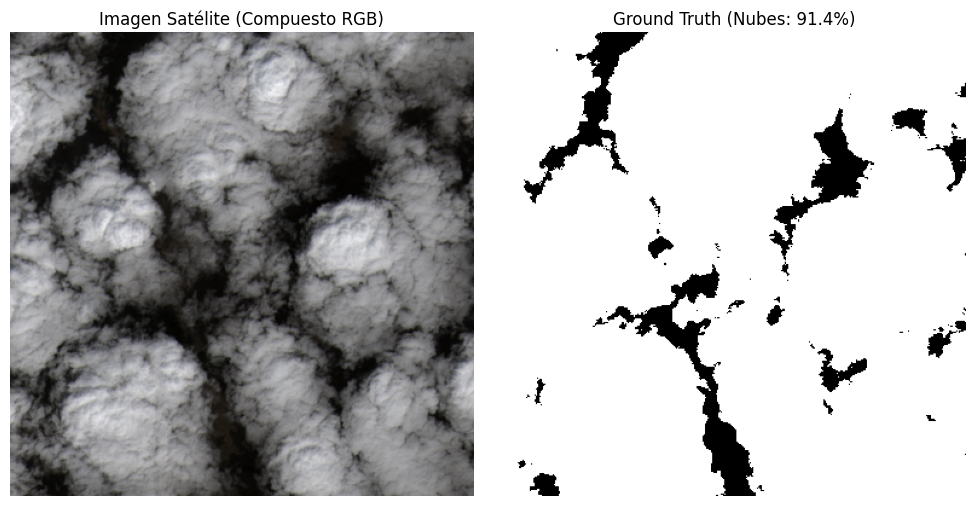

In [15]:
import os
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt

class CloudDataset(Dataset):
    def __init__(self, base_dir='data/38-Cloud_training'):
        self.base_dir = base_dir
        self.gt_dir = os.path.join(base_dir, 'train_gt')
        #filtrado de cualquier archivo basura que pudiera haber en la carpeta (solo .tif)
        self.gt_files = [f for f in os.listdir(self.gt_dir) if f.lower().endswith('.tif')]

    def __len__(self):
        return len(self.gt_files)

    def __getitem__(self, idx):
        gt_name = self.gt_files[idx]
        patch_id = gt_name.replace('gt_', '')

        red_path = os.path.join(self.base_dir, 'train_red', f'red_{patch_id}')
        green_path = os.path.join(self.base_dir, 'train_green', f'green_{patch_id}')
        blue_path = os.path.join(self.base_dir, 'train_blue', f'blue_{patch_id}')
        nir_path = os.path.join(self.base_dir, 'train_nir', f'nir_{patch_id}')
        gt_path = os.path.join(self.gt_dir, gt_name)

        r = np.array(Image.open(red_path)).astype(np.float32)
        g = np.array(Image.open(green_path)).astype(np.float32)
        b = np.array(Image.open(blue_path)).astype(np.float32)
        nir = np.array(Image.open(nir_path)).astype(np.float32)

        img = np.stack([r, g, b, nir], axis=0)

        for i in range(4):
            min_val = img[i].min()
            max_val = img[i].max()
            if max_val - min_val > 0:
                img[i] = (img[i] - min_val) / (max_val - min_val)

        mask = np.array(Image.open(gt_path)).astype(np.float32)
        # Si el píxel tiene cualquier valor mayor que cero (por ejemplo 255), lo convierte en 1.0 (nube); si no, en 0.0 (despejado).
        mask = np.where(mask > 0, 1.0, 0.0)
        mask = np.expand_dims(mask, axis=0)

        return torch.tensor(img), torch.tensor(mask)

# 1. Instanciar el Dataset y DataLoader
print("Cargando y procesando Dataset...")
dataset = CloudDataset(base_dir='data/38-Cloud_training')
print(f"Total de imágenes encontradas: {len(dataset)}")

# Uso batch_size=8
dataloader = DataLoader(dataset, batch_size=8, shuffle=True)

# 2. Extraer un lote y comprobar dimensiones
images, masks = next(iter(dataloader))
print(f"Forma del tensor de imágenes: {images.shape} -> (Batch, Canales, Alto, Ancho)")
print(f"Forma del tensor de máscaras: {masks.shape} -> (Batch, Canales, Alto, Ancho)")

# 3. Visualización de una muestra del batch
idx_to_show = 0
img_viz = images[idx_to_show, :3, :, :].numpy().transpose(1, 2, 0)
mask_viz = masks[idx_to_show, 0, :, :].numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_viz)
axes[0].set_title("Imagen Satélite (Compuesto RGB)")
axes[0].axis('off')

axes[1].imshow(mask_viz, cmap='gray', vmin=0, vmax=1)
axes[1].set_title(f"Ground Truth (Nubes: {mask_viz.mean()*100:.1f}%)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 3. Arquitectura del Modelo: U-Net

Implementación una U-Net desde cero utilizando torch.nn. Esta arquitectura recibe un tensor de entrada de 4 canales (Batch, 4, 384, 384) y devuelve un mapa de predicción de 1 canal (Batch, 1, 384, 384) donde cada píxel representa la probabilidad de que haya una nube.

La red se divide en tres partes:
1. **Encoder (Bajada / Contracción):** Aplica bloques de doble convolución (DoubleConv) seguidos de operaciones MaxPool2d que reducen el tamaño espacial a la mitad en cada nivel (384 -> 192 -> 96 -> 48), mientras duplican la profundidad de canales (32 -> 64 -> 128 -> 256). Aquí la red pierde detalle de dónde están las cosas, pero aprende qué son (contexto).
2. **Bottleneck (Cuello de botella):** Es la base de la "U" (resolución 24x24 con 512 canales), donde se condensa la información más abstracta de la imagen.
3. **Decoder (Subida / Expansión) y Skip Connections:** Utiliza convoluciones transpuestas (ConvTranspose2d) para volver a ampliar la imagen hasta los 384x384 píxeles originales. En cada escalón de subida, concatenamos (torch.cat) los mapas de características guardados durante la bajada (Skip Connections). Esto permite recuperar los bordes exactos de las nubes sin perder el contexto aprendido.

In [16]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    # Bloque básico de U-Net: (Convolución -> BatchNorm -> ReLU) x 2
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels=4, out_channels=1, features=[32, 64, 128, 256]):
        super().__init__()
        self.downs = nn.ModuleList()
        self.ups = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # 1. Encoder (Bajada)
        for feature in features:
            self.downs.append(DoubleConv(in_channels, feature))
            in_channels = feature

        # 2. Bottleneck (Base de la U)
        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)

        # 3. Decoder (Subida)
        for feature in reversed(features):
            # Convolución transpuesta para duplicar el tamaño espacial
            self.ups.append(
                nn.ConvTranspose2d(feature * 2, feature, kernel_size=2, stride=2)
            )
            # Doble convolución tras concatenar la Skip Connection (feature * 2)
            self.ups.append(DoubleConv(feature * 2, feature))

        # Capa final 1x1 para proyectar al número de canales de salida (1 máscara)
        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skip_connections = []

        # Bajada guardando las skip connections
        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        # Invertimos la lista para emparejarlas de abajo hacia arriba
        skip_connections = skip_connections[::-1]

        # Subida concatenando las skip connections
        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x) # Upsampling
            skip_connection = skip_connections[idx // 2]

            # Concatenamos a lo largo de la dimensión de los canales (dim=1)
            concat_skip = torch.cat((skip_connection, x), dim=1)
            x = self.ups[idx + 1](concat_skip) # DoubleConv

        return self.final_conv(x)

# PRUEBA DE VERIFICACIÓN
# Instancio el modelo y se envía a la GPU
model = UNet(in_channels=4, out_channels=1).to(device)

# Se pasa el lote 'images' que se carga en el paso anterior por la red (sin entrenar aún)
with torch.no_grad():
    test_output = model(images.to(device))

print(f"Forma de entrada: {images.shape}")
print(f"Forma de salida de la U-Net: {test_output.shape}")

Forma de entrada: torch.Size([8, 4, 384, 384])
Forma de salida de la U-Net: torch.Size([8, 1, 384, 384])


## 4. Entrenamiento del Modelo

Antes de entrenar, se divide el dataset en entrenamiento (90%) y validación (10%) para poder evaluar posteriormente la capacidad de generalización de la red sobre imágenes nunca vistas.

Configuramos tres elementos fundamentales:
1. **Función de Pérdida (BCEWithLogitsLoss):** Mide el error píxel a píxel entre la predicción de la red y la máscara real. Combina internamente una función Sigmoide (que aplasta los números de salida al rango [0, 1] como probabilidades) con la Entropía Cruzada Binaria, garantizando estabilidad numérica.
2. **Optimizador (Adam):** Algoritmo encargado de actualizar los pesos de la U-Net tras calcular los gradientes (loss.backward()), usando una tasa de aprendizaje (learning rate) de 1e-4.
3. **Épocas:** Se entrena durante 3 épocas y se guardan los pesos aprendidos en un archivo .pth.

In [17]:
import torch.optim as optim
from torch.utils.data import random_split
from tqdm import tqdm

# 1. Dividir el dataset: 90% entrenamiento, 10% validación (para el examen final)
train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2)

print(f"Imágenes para entrenar: {len(train_dataset)} | Imágenes reservadas para test: {len(val_dataset)}")

# 2. Configurar función de pérdida y optimizador
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# 3. Bucle de entrenamiento
EPOCHS = 3

for epoch in range(EPOCHS):
    model.train() # Ponemos la red en modo entrenamiento
    running_loss = 0.0

    # Barra de progreso para ver el avance en directo
    loop = tqdm(train_loader, desc=f"Época [{epoch+1}/{EPOCHS}]")

    for images, masks in loop:
        # 1. Mover datos a la GPU
        images = images.to(device)
        masks = masks.to(device)

        # 2. Limpiar gradientes anteriores
        optimizer.zero_grad()

        # 3. Forward: predicción de la U-Net
        predictions = model(images)

        # 4. Calcular cuánto se equivocó
        loss = criterion(predictions, masks)

        # 5. Backward: calcular derivadas y ajustar pesos
        loss.backward()
        optimizer.step()

        # Actualizar métricas en la barra
        running_loss += loss.item()
        loop.set_postfix(loss=f"{loss.item():.4f}")

    epoch_loss = running_loss / len(train_loader)
    print(f"--> Resumen Época {epoch+1}: Error medio (Loss) = {epoch_loss:.4f}\n")

# 4. Guardar los pesos entrenados del modelo
torch.save(model.state_dict(), "unet_cloud_segmentation.pth")
print("¡Entrenamiento finalizado y modelo guardado como 'unet_cloud_segmentation.pth'!")

Imágenes para entrenar: 7560 | Imágenes reservadas para test: 840


Época [1/3]: 100%|██████████| 945/945 [06:14<00:00,  2.52it/s, loss=0.2187]


--> Resumen Época 1: Error medio (Loss) = 0.3571



Época [2/3]: 100%|██████████| 945/945 [06:17<00:00,  2.50it/s, loss=0.4239]


--> Resumen Época 2: Error medio (Loss) = 0.2571



Época [3/3]: 100%|██████████| 945/945 [06:19<00:00,  2.49it/s, loss=0.1361]

--> Resumen Época 3: Error medio (Loss) = 0.2104

¡Entrenamiento finalizado y modelo guardado como 'unet_cloud_segmentation.pth'!


##  Paso 5 (Evaluación Visual e Inferencia)

Precisión píxel a píxel (Accuracy): 94.58%
Solapamiento real de nubes (IoU): 92.02%



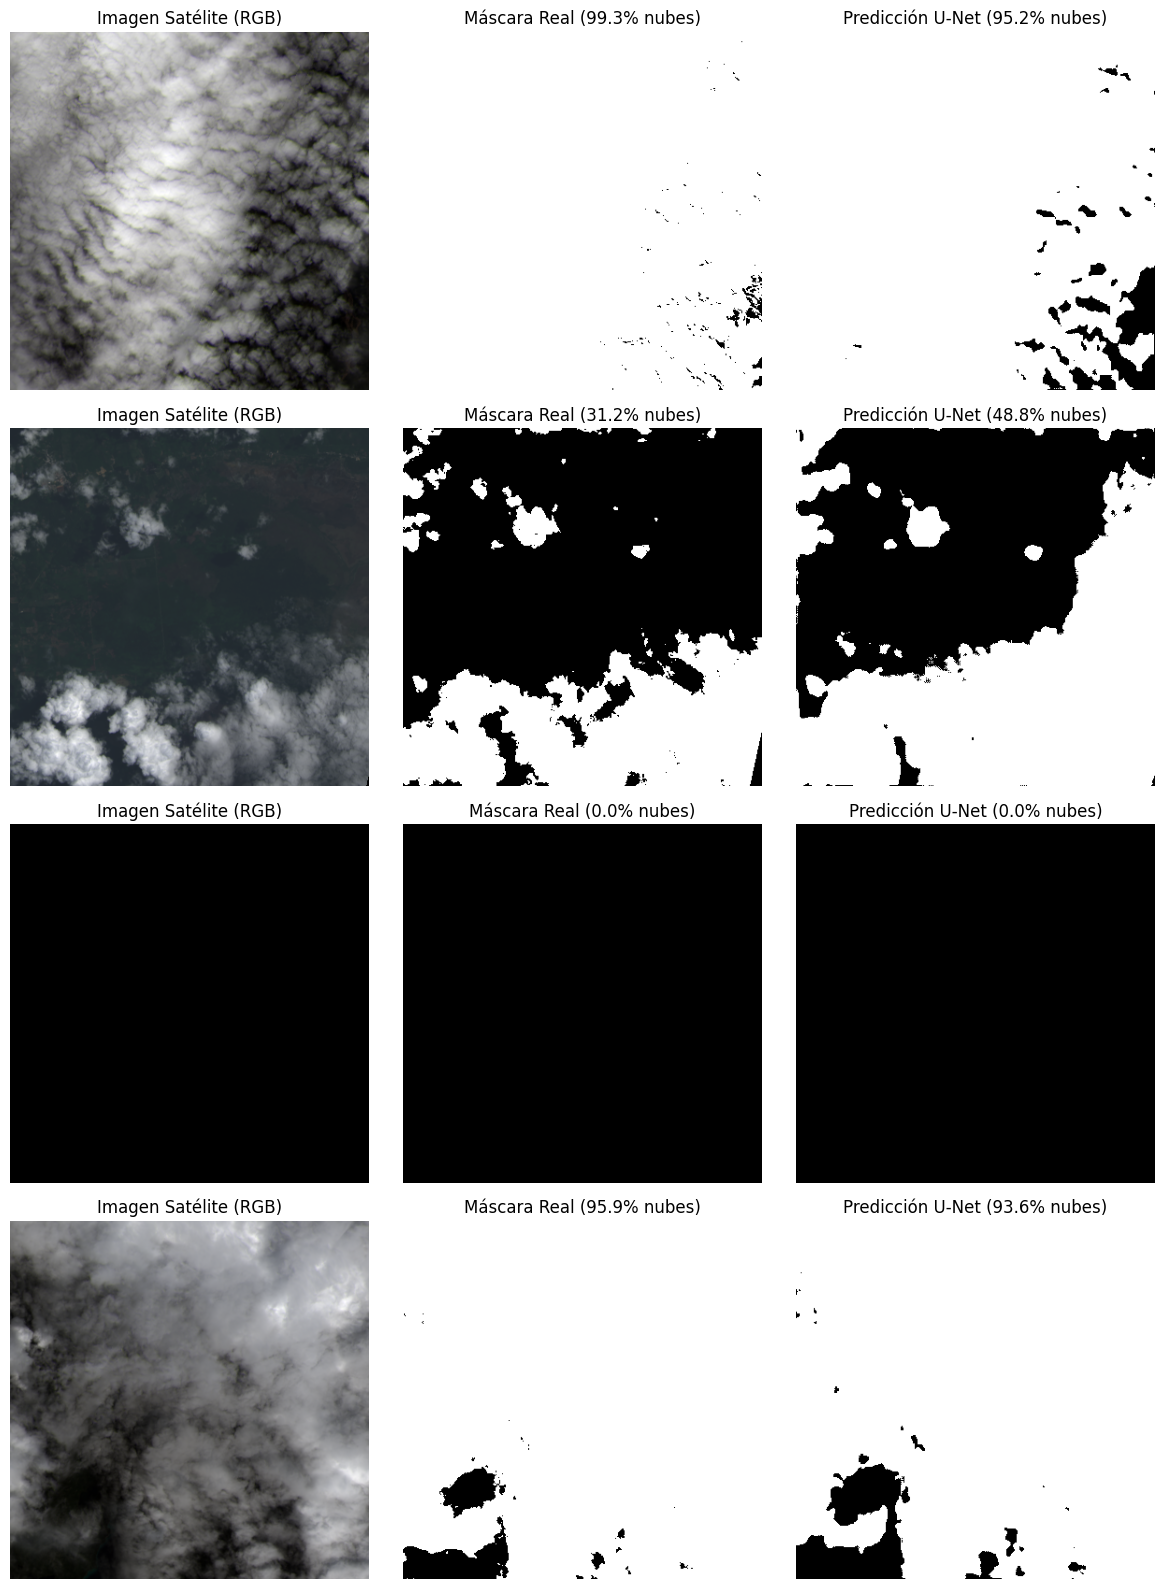

In [19]:
import matplotlib.pyplot as plt

# 1. Se pone  el modelo en modo evaluación
model.eval()

# 2. Coger un lote de imágenes nuevas del conjunto de validación
val_images, val_masks = next(iter(val_loader))
val_images_gpu = val_images.to(device)

# 3. Hacemos la predicción sin calcular derivadas
with torch.no_grad():
    raw_predictions = model(val_images_gpu)
    # Convertir logits a probabilidades [0, 1] y aplicamos umbral 0.5
    probs = torch.sigmoid(raw_predictions)
    pred_masks = (probs > 0.5).float().cpu()

# 4. Calcular métricas reales en porcentaje sobre este lote
accuracy = (pred_masks == val_masks).float().mean().item() * 100
intersection = (pred_masks * val_masks).sum().item()
union = ((pred_masks + val_masks) > 0).float().sum().item()
iou = (intersection / union * 100) if union > 0 else 100.0

print(f"Precisión píxel a píxel (Accuracy): {accuracy:.2f}%")
print(f"Solapamiento real de nubes (IoU): {iou:.2f}%\n")

# 5. Visualizar 4 ejemplos lado a lado: Satélite | Realidad | Tu U-Net
num_examples = 4
fig, axes = plt.subplots(num_examples, 3, figsize=(12, 4 * num_examples))

for i in range(num_examples):
    img_rgb = val_images[i, :3, :, :].numpy().transpose(1, 2, 0)
    gt_mask = val_masks[i, 0, :, :].numpy()
    pred_mask = pred_masks[i, 0, :, :].numpy()

    # Columna 1: Imagen Satélite
    axes[i, 0].imshow(img_rgb)
    axes[i, 0].set_title("Imagen Satélite (RGB)")
    axes[i, 0].axis("off")

    # Columna 2: Máscara Real (Ground Truth)
    axes[i, 1].imshow(gt_mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title(f"Máscara Real ({gt_mask.mean()*100:.1f}% nubes)")
    axes[i, 1].axis("off")

    # Columna 3: Predicción de la U-Net
    axes[i, 2].imshow(pred_mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title(f"Predicción U-Net ({pred_mask.mean()*100:.1f}% nubes)")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.savefig("resultados_segmentacion.png", dpi=150)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')